In [14]:
import astroML 

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import ascii
# from astroML.time_series.bayesian_blocks
from astropy.stats import bayesian_blocks

In [16]:
# !pip install astroML

In [29]:
from astropy.table import Table

In [32]:
path = "/media/mittu/ROR WD/Swift_sample/"

In [37]:
grb_table = ascii.read(path+'name.txt')
grb_table = grb_table[:-1]
grb_table[-5:]

GRB_name,GRB_ID
str10,str8
GRB211024B,01081073
GRB220101A,01091527
GRB220117A,01093592
GRB221009A,01126853
GRB221009A,01126854


In [61]:
grb_id_list = []
min_bin_pos = []
min_bin_width = []
no_data_grb = []
for grb_id in grb_table['GRB_ID']:
    try:
        data = ascii.read(f"/media/mittu/ROR WD/Swift_sample/BATBAT/{grb_id}/bat/bat_flux_timedel0.064_BATBAND.qdp", header_start = None, data_start=3, comment='!')
        a= np.array(data['col1'])
        b= np.array(data['col4'])
        c= np.array(data['col5'])
    
        edges = bayesian_blocks(
        a, b, sigma=c,
        fitness='measures', p0=0.01
        )

        t = []
        f = []
        for le, re in zip(edges[:-1], edges[1:]):
            idx = (le <= a) & (a < re)
            tf = np.mean(b[idx])
            t.append(0.5*(le+re))
            f.append(tf)

        plt.figure()
        _ = plt.plot(a, b, alpha=0.5, c='0.5')
        _ = plt.step(t, f, 'k')
        plt.savefig(f'plots/{grb_id}.png')
        plt.close()

        y = (edges[1:]-edges[:-1])/2
        idx = np.argmin(y)
        grb_id_list.append(grb_id)
        min_bin_pos.append(edges[idx])
        min_bin_width.append(y[idx])
    except:
        no_data_grb.append(grb_id)

/home/mittu/miniconda3/lib/python3.9/site-packages/astropy/stats/bayesian_blocks.py:337: RuntimeWarning: divide by zero encountered in divide
  ak_raw = np.ones_like(x) / sigma ** 2
/home/mittu/miniconda3/lib/python3.9/site-packages/astropy/stats/bayesian_blocks.py:339: RuntimeWarning: invalid value encountered in divide
  bk_raw = x / sigma ** 2


In [62]:
t = Table(
    [grb_id_list, min_bin_pos, min_bin_width],
    names = ['grb', 'min_bin_pos', 'min_bin_width']
)
t

grb,min_bin_pos,min_bin_width
str8,float64,float64
00111063,24.6677999868989,0.4479999989271253
00111622,-86.4345999956131,186.43199999630454
00117504,51.170200005173655,0.5120000019669746
00147478,0.127999991178513,0.14400000870227797
00148225,1.865600019693375,4.735999993979938
00148833,145.899200007319,0.6400000005962454
00150314,-1.31379997730255,12.607999995350827
00153514,125.456599995494,4.447999998927003
00155242,13.618799999356249,0.6719999983906755


In [63]:
t.write('tmvs.txt', format='ascii', overwrite=True)

In [64]:
no_data_grb

['00020028', '00295492', '00637899', '01126854']

In [18]:
# data = data[(-10<data['col1']) & (data['col1'] < 150)]

In [19]:
a= np.array(data['col1'])
b= np.array(data['col4'])
c= np.array(data['col5'])

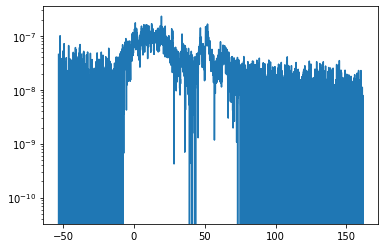

In [20]:
plt.plot(a,b)
plt.yscale("log")
# plt.xlim(-10,100)

In [21]:
edges = bayesian_blocks(
    a, b, sigma=c,
    fitness='measures', p0=0.01
)

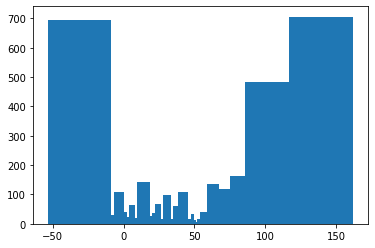

In [22]:
freq, bins, _ = plt.hist(a, bins=edges)

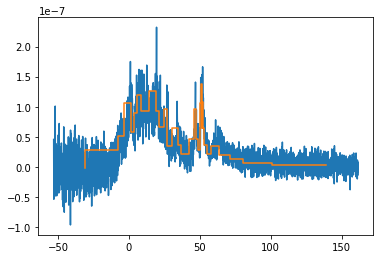

In [23]:
t = []
f = []
for le, re in zip(edges[:-1], edges[1:]):
    idx = (le <= a) & (a < re)
    tf = np.mean(b[idx])
    t.append(0.5*(le+re))
    f.append(tf)

plt.plot(a, b)
plt.step(t, f)
# plt.yscale('log')

In [24]:
y = (edges[1:]-edges[:-1])/2
idx = np.argmin(y)
edges[idx], y[idx]

(51.70919996500015, 0.03200000524522295)

In [25]:
c

array([2.59772411e-08, 2.49072616e-08, 2.51617997e-08, ...,
       1.14574254e-08, 1.15944347e-08, 1.26722124e-08])

In [27]:
# edges = bayesian_blocks(
#     a, b, sigma=(c)/2,
#     fitness='measures', p0=0.005
# )
# #print(edges)
# x = (edges[1:]+edges[:-1])/2
# y = (edges[1:]-edges[:-1])/2
# print(np.min(x))
# print(np.min(y))

# fig, ax0 = plt.subplots()

# aflx = []
# for i1 in range(0, len(x)):
#     xx = []
#     for ii in range(0, len(a)):
#         if (a[ii] >= edges[i1]) & (a[ii] <= edges[i1+1]):
#             xx.append(b[ii])
#             aflx.append(np.mean(xx))
# ax0.plot(a, b, marker='.',markersize=1,lw = 1.5,ls='-',drawstyle='steps-mid',color='k',alpha=0.6, markerfacecolor='none', markeredgecolor='k',label= r'$\rm (15 - 350)$ $\rm keV$')
# ax0.plot(edges, np.append(aflx, aflx[-1]), linestyle='-',drawstyle='steps-post',color='r',linewidth=2.0)

In [28]:
edges

array([-5.30908000e+01, -5.20348001e+01, -5.19708000e+01, -4.70428000e+01,
       -4.63388000e+01, -4.58908001e+01, -4.55708000e+01, -4.12828000e+01,
       -4.12188000e+01, -4.10908000e+01, -3.48828000e+01, -3.40508000e+01,
       -3.25148000e+01, -2.30428000e+01, -2.28508000e+01, -1.88188000e+01,
       -1.68348000e+01, -1.66428000e+01, -1.45948001e+01, -1.43388000e+01,
       -1.24188001e+01, -1.21628000e+01, -1.18428000e+01, -8.51480004e+00,
       -6.78680003e+00, -5.69880003e+00, -5.37880003e+00, -1.47480005e+00,
        6.11999631e-02,  1.02119994e+00,  1.08519995e+00,  1.40519994e+00,
        2.55719995e+00,  3.96519995e+00,  4.28519994e+00,  4.34919995e+00,
        6.20519996e+00,  6.84519994e+00,  7.35719997e+00,  7.99719995e+00,
        8.38119996e+00,  8.50919998e+00,  9.34119996e+00,  9.72519994e+00,
        9.98119998e+00,  1.12612000e+01,  1.23492000e+01,  1.27332000e+01,
        1.32452000e+01,  1.39492000e+01,  1.43332000e+01,  1.72772000e+01,
        1.74692000e+01,  